# Phase 2 demo: the trained U-Net on real and new layouts

This notebook runs the final Phase 2 model on a few examples and shows its predictions next to the simulations.

1. **A real neighbourhood the model has never seen**, compared cell by cell with the large-eddy simulation.
2. **The same neighbourhood with the wind from another direction.**
3. **A layout that was never simulated**, with an uncertainty map.

Every example can be changed and run again: any of the 482 development cases, any wind direction, any building layout.

**Requirements.** `uv sync`; the trained weights in `results/checkpoints/` (see *Using the trained model* in the README); and, for examples 1 and 2, the raw UrbanTALES files in `data/raw/` (`pipeline/S01_data_ingestion`). It runs in about a minute on a laptop GPU, and also on a CPU, more slowly.

**Fair examples only.** A development case is predicted only by the three networks (one per training seed) of the fold that held its city or layout family out, so those networks never saw it; this reproduces the reported out-of-fold predictions. The frozen test cases are not used here: only the S16 scoring script opens them.

In [1]:
import os, pathlib, time
REPO = pathlib.Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists() and REPO != REPO.parent:
    REPO = REPO.parent
os.chdir(REPO)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from urbanwind.data import load_case
from urbanwind.metrics import case_metrics
from urbanwind.dl.cache import dev_cases
from urbanwind.dl.datasets import predict_arrays
from urbanwind.dl.predict import FINAL_CONFIG, checkpoint_paths, layout_arrays, predict_layout
from urbanwind.dl.train import inference, load_best, load_config, pick_device

cfg, device = load_config(FINAL_CONFIG), pick_device()
DEV = dev_cases()
PHASE1 = (pd.read_csv("pipeline/S11_unet_baseline/outputs/per_case_metrics.csv")
          .query("run == 's07_pixel_gbm'").set_index("case")["r2"])
print(f"device: {device} | final model: {FINAL_CONFIG.relative_to(REPO)} | development cases: {len(DEV)}")

device: mps | final model: pipeline/S13_hybrid/configs/unet_tuned_e200.yaml | development cases: 482


## The model at a glance

| Setting | Value | Why |
| --- | --- | --- |
| Task | U/u\* at 1.75 m in every open 1 m cell | the wind a pedestrian feels, on one scale for every case |
| Inputs | 5 channels: building height / 16 m, building mask, periodic distance to the nearest wall / 16 m, cos and sin of the wind angle | only what a designer has before simulating; no coordinates, because the domains are periodic |
| Wind frame | every case turned by quarter turns (and a transpose) so the wind blows within 0° to 45° of +x; turned back after prediction | the simulations have no Coriolis force, so this is exact and the network need not learn every direction |
| Architecture | periodic U-Net: 4 levels of 24, 48, 96, 192 channels, a 384-channel bottleneck | image in, image out; deep levels see the street layout, skip connections keep the walls in place |
| Parameters | 4,860,313 per network | tuning halved the first version (8,636,961) and lowered the error |
| Padding | circular in every convolution and upsampling | the simulated domains repeat; zero padding cost 0.031 pooled R² |
| Normalisation | GroupNorm, 8 groups | batches are 16 patches, and whole cities of other sizes are predicted one at a time |
| Activations | ReLU inside; softplus at the output | ReLU trains well with He initialisation; softplus keeps the speed positive |
| Initialisation | He (Kaiming normal) | suited to ReLU layers |
| Loss | L1 on open ground, a 16-cell patch border excluded | best of seven losses tried; MSE cost 0.026 pooled R² |
| Optimiser | AdamW, learning rate 3.6e-4, weight decay 6.5e-5, cosine decay to 1e-5 | from an Optuna study of 33 trials |
| Training data | 16 patches of 256 × 256 cells per step, 70 steps per epoch, 200 epochs | the validation error was still falling after 100 epochs in 14 of 15 runs |
| Regularisation | spatial dropout 0.08; mirror and 45° transpose augmentation; weight averaging (EMA 0.999); early stopping, patience 30 | the symmetries are exact; augmentation is worth 0.030 pooled R² |
| Precision | mixed precision, loss in float32, gradients clipped at 1.0 | speed on T4 GPUs |
| Final model | 3 seeds × 5 folds = 15 networks; the seeds are averaged | the average beats every single network |

**Why this model and not others** (pooled R² on all 482 development cases, unseen cities, grouped five-fold cross-validation):

| Model | Pooled R² | Median per-case R² |
| --- | --- | --- |
| Phase 1 pixel model (LightGBM, hand-made features) | 0.591 | 0.304 |
| Fourier neural operator | 0.558 | 0.355 |
| Res-U-Net | 0.671 to 0.683 | 0.529 to 0.530 |
| Attention U-Net | 0.679 to 0.694 | 0.526 to 0.529 |
| U-Net, 100 epochs (three seeds) | 0.709 to 0.712 | 0.560 to 0.595 |
| **Final U-Net, 200 epochs, three seeds averaged** | **0.734** | **0.629** |
| **Final U-Net on the frozen test set (53 cases, scored once)** | **0.840** (Phase 1: 0.680) | **0.655** (Phase 1: 0.351) |

A ConvNeXt U-Net was also screened on fold 0 and scored below every U-Net seed (pooled R² 0.741 against 0.789 to 0.802).

## How the model is stored

Each of the 15 networks is a PyTorch file (`.pt`, written with `torch.save`) that holds only its learned weights, as a dictionary of tensors. The architecture comes from the configuration file, so loading means building the network from the configuration and putting the weights into it.

In [2]:
path = REPO / "results/checkpoints/s13_unet_tuned_e200_seed0/fold0.pt"
weights = torch.load(path, map_location="cpu")
print(f"{path.relative_to(REPO)}: {path.stat().st_size / 1e6:.0f} MB, {len(weights)} weight tensors, "
      f"{sum(t.numel() for t in weights.values()):,} numbers")
print("first tensors:", {name: tuple(t.shape) for name, t in list(weights.items())[:3]})

net = load_best(cfg, path, device).eval()   # builds the U-Net from the config, then loads the weights
print(type(net).__name__, f"with {sum(p.numel() for p in net.parameters()):,} parameters, on {device}")

results/checkpoints/s13_unet_tuned_e200_seed0/fold0.pt: 19 MB, 82 weight tensors, 4,860,313 numbers
first tensors: {'down.0.0.weight': (24, 5, 3, 3), 'down.0.0.bias': (24,), 'down.0.1.weight': (24,)}


UNet with 4,860,313 parameters, on mps


## 1. A real neighbourhood the model has never seen

`predict_unseen(case)` loads a development case from the raw files, predicts it with the three networks of its own fold, and compares the result with the simulation: the per-case R² (the pattern inside the neighbourhood), the mean absolute error and the error of the 95th-percentile speed, next to the Phase 1 pixel model on the same case.

AU-Ade-V1_d00 (realistic, wind towards 0 deg, 1 m grid, 157,562 open cells): predicted by the 3 networks of fold 1 in 0.88 s
  per-case R2 0.588 (Phase 1 pixel model: 0.398) | MAE 0.723 u* | error of the 95th-percentile speed -0.69 u*


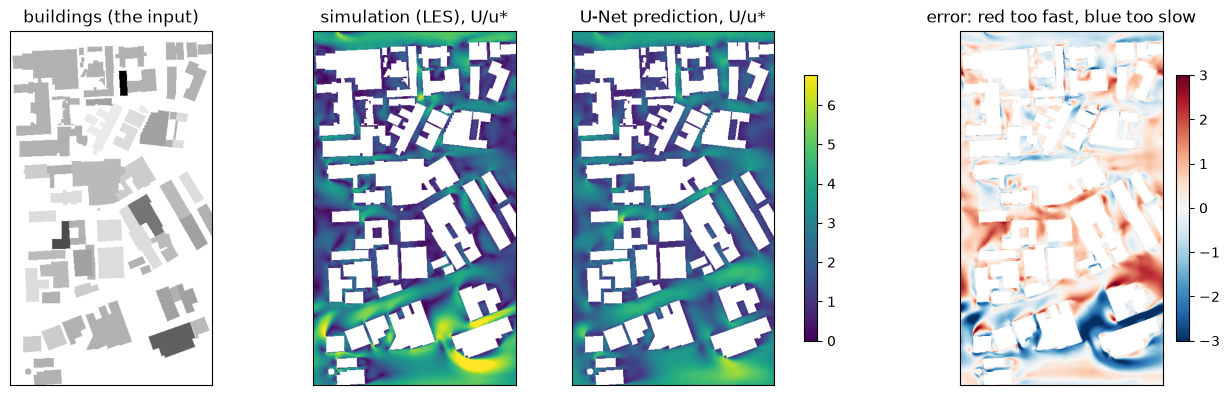

In [3]:
_networks = {}

def fold_networks(fold):
    # the three networks (seeds 0, 1, 2) that were trained without this fold
    if fold not in _networks:
        _networks[fold] = [load_best(cfg, p, device).eval() for p in checkpoint_paths(cfg, (0, 1, 2), [fold])]
    return _networks[fold]


def predict(nets, H, dx, wind_dir_deg):
    # average of the networks on the input grid, from the building raster and the wind direction only
    arrays = layout_arrays(H, dx, wind_dir_deg)
    autocast = torch.autocast(device.type, dtype=torch.float16, enabled=cfg["amp"] and device.type != "cpu")
    with torch.no_grad(), autocast:
        preds = [predict_arrays(net, arrays, device, mirror_tta=cfg["mirror_tta"], upsample=cfg["native_upsample"],
                                **inference(cfg)) for net in nets]
    return np.mean(preds, axis=0)


def predict_unseen(case, show=True):
    if case not in DEV.index:
        raise ValueError(f"{case} is not a development case (frozen test cases are opened only by S16)")
    fold, c = int(DEV.loc[case, "fold"]), load_case(case)
    nets = fold_networks(fold)
    t0 = time.perf_counter()
    pred = predict(nets, c["H"], c["dx"], c["wind_dir_deg"])
    seconds = time.perf_counter() - t0
    truth = c["U"]
    ok = np.isfinite(truth)
    m = case_metrics(truth[ok].astype(float), pred[ok].astype(float))
    print(f"{case} ({DEV.loc[case, 'subset']}, wind towards {c['wind_dir_deg']:g} deg, {c['dx']:g} m grid, "
          f"{ok.sum():,} open cells): predicted by the 3 networks of fold {fold} in {seconds:.2f} s")
    print(f"  per-case R2 {m['r2']:.3f} (Phase 1 pixel model: {PHASE1.get(case, np.nan):.3f}) | "
          f"MAE {m['mae']:.3f} u* | error of the 95th-percentile speed {m['delta_p95']:+.2f} u*")
    if show:
        pred_open = np.where(ok, pred, np.nan)
        vmax = np.nanpercentile(truth, 99)
        fig, ax = plt.subplots(1, 4, figsize=(16, 4.6))
        ax[0].imshow(np.where(c["H"] > 0, c["H"], np.nan), origin="lower", cmap="Greys", vmin=0)
        ax[0].set_title("buildings (the input)")
        for a, img, title in [(ax[1], truth, "simulation (LES), U/u*"), (ax[2], pred_open, "U-Net prediction, U/u*")]:
            im = a.imshow(img, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
            a.set_title(title)
        fig.colorbar(im, ax=ax[1:3], shrink=0.75)
        im = ax[3].imshow(pred_open - truth, origin="lower", cmap="RdBu_r", vmin=-3, vmax=3)
        ax[3].set_title("error: red too fast, blue too slow")
        fig.colorbar(im, ax=ax[3], shrink=0.75)
        for a in ax:
            a.set_xticks([]); a.set_yticks([])
        plt.show()
    return pred, m


_ = predict_unseen("AU-Ade-V1_d00")    # a real neighbourhood in Adelaide

UA0625_d45 (idealized, wind towards 45 deg, 0.5 m grid, 229,440 open cells): predicted by the 3 networks of fold 1 in 0.27 s
  per-case R2 0.981 (Phase 1 pixel model: 0.896) | MAE 0.086 u* | error of the 95th-percentile speed -0.03 u*


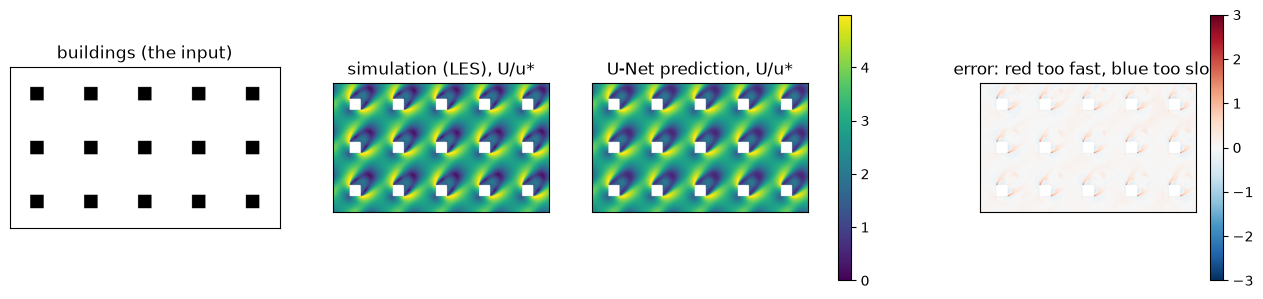

In [4]:
_ = predict_unseen("UA0625_d45")       # an idealized array, wind at 45 degrees

**Try another case.** Any development case works; the cell below lists a few of each kind. The first call for a new fold loads its three networks, which takes a moment.

In [5]:
rng = np.random.default_rng()
for subset in ("realistic", "idealized"):
    names = DEV.index[DEV["subset"] == subset]
    print(f"{subset}: {', '.join(rng.choice(names, 6, replace=False))}")

realistic: US-Bos-U1_d90, CN-BE-V1_d75, AU-Mel-U1_d00, IT-ROM-V2_d00, US-Pho-U3_d30, AU-Can-V1_d00
idealized: VA64-CL-56_d45, US64_d00, VA0625-CL-28_d00, VS25-HR-56_d00, VS4444-SM-28_d45, VS25-HR-28_d00


## 2. The same neighbourhood with the wind from another direction

UrbanTALES simulated this Adelaide district with the wind blowing towards 0° and towards 90°. Only the wind direction changes in the input; the fast channels should move to the streets aligned with the new wind.

AU-Ade-V1_d00 (realistic, wind towards 0 deg, 1 m grid, 157,562 open cells): predicted by the 3 networks of fold 1 in 0.58 s
  per-case R2 0.588 (Phase 1 pixel model: 0.398) | MAE 0.723 u* | error of the 95th-percentile speed -0.69 u*


AU-Ade-V1_d90 (realistic, wind towards 90 deg, 1 m grid, 157,562 open cells): predicted by the 3 networks of fold 1 in 0.61 s
  per-case R2 0.615 (Phase 1 pixel model: 0.333) | MAE 0.652 u* | error of the 95th-percentile speed -0.11 u*


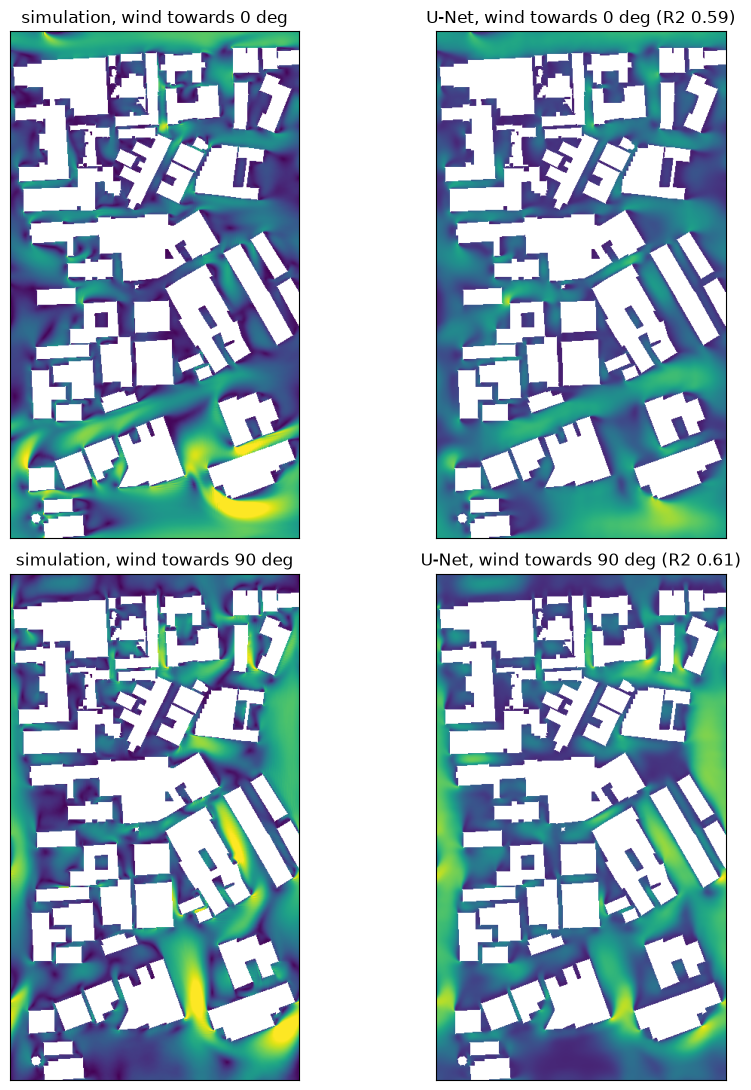

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(10, 11))
for row, case in enumerate(["AU-Ade-V1_d00", "AU-Ade-V1_d90"]):
    pred, m = predict_unseen(case, show=False)
    truth = load_case(case)["U"]
    vmax = np.nanpercentile(truth, 99)
    for col, (img, title) in enumerate([(truth, "simulation"), (np.where(np.isfinite(truth), pred, np.nan), "U-Net")]):
        ax[row, col].imshow(img, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
        wind = case.split("_d")[1]
        ax[row, col].set_title(f"{title}, wind towards {int(wind)} deg" + (f" (R2 {m['r2']:.2f})" if col else ""))
        ax[row, col].set_xticks([]); ax[row, col].set_yticks([])
plt.tight_layout(); plt.show()

## 3. A layout that was never simulated

For a new layout, every one of the 15 networks is out of sample, so all of them are averaged; their spread is the uncertainty map. Edit the buildings (heights in metres) and the wind direction (degrees, the direction the wind blows towards, 0 = towards +x) and run the cell again.

The same prediction is one command: `uv run python -m urbanwind.dl.predict --height layout.npy --wind-dir 30 --out wind.npz --png wind.png`.

15 networks in 1.8 s | mean U/u* over open ground 1.42 | mean spread 0.164 u*


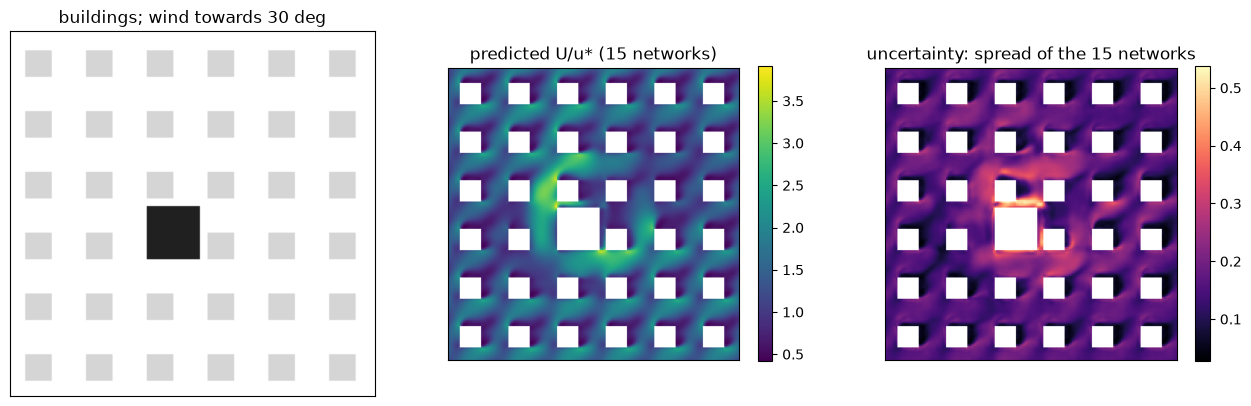

In [7]:
H = np.zeros((192, 192))
for r in range(8, 192, 32):
    for c in range(8, 192, 32):
        H[r:r + 14, c:c + 14] = 12.0      # an array of 14 m x 14 m blocks, 12 m tall
H[72:100, 72:100] = 40.0                  # one 40 m tower
wind_dir = 30.0

t0 = time.perf_counter()
out = predict_layout(H, dx=1.0, wind_dir_deg=wind_dir)
print(f"{out['n_networks']} networks in {time.perf_counter() - t0:.1f} s | mean U/u* over open ground "
      f"{np.nanmean(out['U']):.2f} | mean spread {np.nanmean(out['spread']):.3f} u*")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].imshow(np.where(H > 0, H, np.nan), origin="lower", cmap="Greys", vmin=0, vmax=45)
ax[0].set_title(f"buildings; wind towards {wind_dir:g} deg")
im = ax[1].imshow(out["U"], origin="lower", cmap="viridis"); ax[1].set_title("predicted U/u* (15 networks)")
fig.colorbar(im, ax=ax[1], shrink=0.8)
im = ax[2].imshow(out["spread"], origin="lower", cmap="magma"); ax[2].set_title("uncertainty: spread of the 15 networks")
fig.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax:
    a.set_xticks([]); a.set_yticks([])
plt.show()

**Reading the result.** There is no simulation to compare with here. The regular blocks repeat the same pattern, as they should on a periodic domain; the tower speeds the air up along its sides and corners; and the networks disagree most next to the tower, where the flow is most complex. That is where a full simulation would still be worth running.